In [40]:
import os
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch

parent_dir = os.path.abspath(os.path.join(os.path.dirname('utils.py'), '..'))
sys.path.append(parent_dir)
import fc

In [41]:
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)

In [42]:
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

In [43]:
cwd = Path.cwd()
cutout_dir = cwd.parent / 'data' / 'cutouts'
table_dir = cwd.parent / 'data' / 'tables'
model_dir = cwd.parent / 'models'

In [44]:
tables = table_dir.rglob('*')
df = pd.concat((pd.read_csv(t) for t in tables), ignore_index=True)

ceers_flux = df.filter(regex='^FLUX_')
ceers_err = df.filter(regex='^FLUXERR_')
primer_flux = df.filter(regex='^f_f') * 10
primer_err = df.filter(regex='^e_f') * 10

df.drop(
    (
        list(ceers_flux.columns)
        + list(primer_flux.columns)
        + list(ceers_err.columns)
        + list(primer_err.columns)
    ),
    inplace=True,
    axis=1,
)

ceers_flux.rename(columns=lambda x: x.replace('FLUX_', 'F'), inplace=True)
primer_flux.rename(columns=lambda x: x.replace('f_f', 'F')[:-1], inplace=True)
ceers_err.rename(columns=lambda x: x.replace('FLUXERR_', 'E'), inplace=True)
primer_err.rename(columns=lambda x: x.replace('e_f', 'E')[:-1], inplace=True)

combined_flux = ceers_flux.combine_first(primer_flux)
combined_err = ceers_err.combine_first(primer_err)

combined_flux = combined_flux.mask(combined_flux <= 0.01, np.nan)
combined_err = combined_err.mask(combined_err <= 0.01, np.nan)
combined_flux = combined_flux.mask(combined_flux == -99, np.nan)
combined_err = combined_err.mask(combined_err == -99, np.nan)

# df = pd.concat([df, combined_flux, combined_err], axis=1)
df = pd.concat([df, np.log10(combined_flux), np.log10(combined_err)], axis=1)

In [45]:
in_features = ['beta', 'Av'] + list(combined_flux.columns)
in_features = ['beta', 'Av', 'F115', 'F150', 'F277', 'F444']
out_feature = 'flag'

bad_av = df['Av'] == -99
bad_beta = df['beta'] == -99
df = df[~bad_beta | ~bad_av]

In [46]:
for col in combined_flux.columns:
    length = len(combined_flux[col].dropna())
    print(col, length)

F115 467
F150 469
F200 473
F277 483
F356 478
F410 471
F444 476
F606 382
F814 426
F105 35
F125 423
F140 347
F160 432
F435 197
F090 342


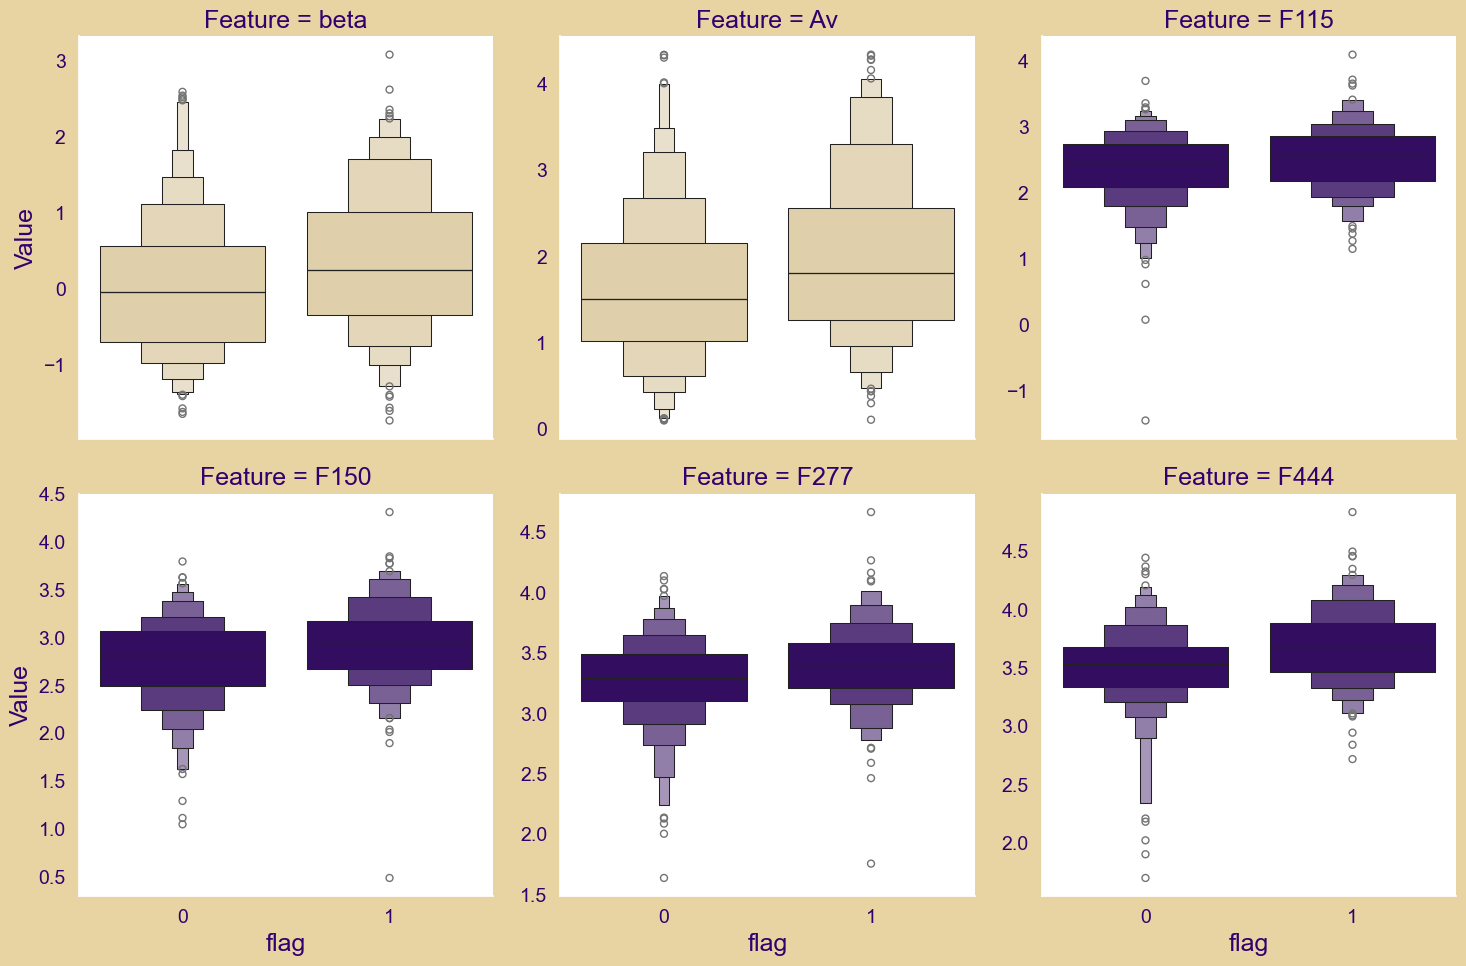

In [47]:
# melt -  basically expands df to each value of each in feature row has its own column

purple = '#32006e'
gold = '#e8d3a2'

feature_colors = {
    'F115': purple,
    'F150': purple,
    'F277': purple,
    'F444': purple,
    'beta': gold,
    'Av': gold,
}

sns.set_theme(
    rc={
        'font.size': 18,
        'axes.labelsize': 18,
        'axes.titlesize': 18,
        'xtick.labelsize': 14,
        'ytick.labelsize': 14,
        'text.color': purple,
        'axes.labelcolor': purple,
    },
)

df_melted = pd.melt(
    df,
    id_vars=[out_feature],
    value_vars=in_features,
    var_name='Feature',
    value_name='Value',
)

# plot them in the sad whisker way
g = sns.catplot(
    data=df_melted,
    x=out_feature,
    y='Value',
    col='Feature',
    kind='boxen',
    sharey=False,
    col_wrap=3,
    hue='Feature',  # Tell seaborn color changes per Feature subplot
    palette=feature_colors,  # Pass your specific dictionary mapping here
    legend=False,
)

g.figure.set_facecolor(gold)
for ax in g.axes.flat:
    ax.set_facecolor('#ffffff')

for ax in g.axes.flat:
    # Update subplot headers (e.g., "Feature = F115")
    if ax.get_title():
        ax.title.set_color(purple)

    # Update tick colors
    ax.tick_params(axis='x', colors=purple)
    ax.tick_params(axis='y', colors=purple)

plt.show()

plt.show()

In [48]:
# helper function to plot a model
from pathlib import Path


def plot_loss(path, model, name=None):
    if name is None:
        name = Path(path).stem
    # load saved model
    checkpoint = torch.load(path, map_location=DEVICE, weights_only=False)

    # get losses and model from file
    model.load_state_dict(checkpoint['model_state_dict'])
    train_losses = checkpoint['train_losses']
    val_losses = checkpoint['val_losses']

    model.eval()

    # plot training and validation loss
    plt.figure(figsize=(12, 8))
    plt.plot(train_losses, label='Train Loss', marker='o')
    plt.plot(val_losses, label='Val Loss', marker='o')
    plt.xlabel('Epoch')
    plt.ylabel('RMSE Loss')
    plt.title(name)
    plt.legend()
    plt.grid(True, linestyle='--', alpha=0.6)
    plt.show()


In [49]:
params = {'num_outputs': 2, 'dropout': 0.6, 'scale': 32, 'input_dim': 6}
model = fc.GalaxyClassifier(**params)
path = r'C:\Users\harty\Code\Galaxy-Classifier\Summer Research\models\fc\model_0.788.pth'

In [50]:
hist = True
if hist:
    import matplotlib.pyplot as plt
    import numpy as np
    import torch
    from torch.utils.data import DataLoader

    model.eval()
    all_preds = []  # model outputs
    all_trues = []  # ground truths

    # set up batches for entire validation set
    val_loader = DataLoader(
        val_set, batch_size=BATCH_SIZE, shuffle=False, num_workers=N_WORKERS
    )

    # predictions for entire validation set
    with torch.no_grad():
        for imgs, labels in val_loader:
            with torch.amp.autocast(DEVICE.type):
                outputs = model(imgs)
            all_preds.append(outputs.cpu().float().numpy())
            all_trues.append(labels.cpu().float().numpy())

    preds_matrix = np.vstack(all_preds)
    trues_matrix = np.vstack(all_trues)

    # get prediction residuals for each galaxy, then compute mean and stdev
    residuals = preds_matrix - trues_matrix
    flattened_residuals = residuals.flatten()
    mean_val = np.mean(flattened_residuals)
    std_val = np.std(flattened_residuals)

    # plot histogram of residuals
    plt.figure()
    plt.hist(flattened_residuals, bins='fd', range=(-0.5, 0.5), color='blue')

    plt.title('Error Distribution')
    plt.xlabel('Residual Value')
    plt.ylabel('N')

    # show mean and std
    plt.text(
        0.25,
        plt.gca().get_ylim()[1] * 0.85,
        f'Mean: {mean_val:+.4f}',
        color='green',
    )
    plt.text(
        0.25,
        plt.gca().get_ylim()[1] * 0.75,
        f'Std: {std_val:.4f}',
        color='orange',
    )

    plt.tight_layout()
    plt.show()

NameError: name 'val_set' is not defined